# **HYPOTHESES TESTING**

## Objectives

* Analyse whether physical activity and nutrition are associated with the calculated overall health score.
* Compare average overall health scores between smoking and non-smoking records.
* Interpret statistical results with effect sizes, confidence intervals, plots, and the EDA findings.

## Inputs
* The cleaned CSV used by the team EDA: cleaned_datasets/holistic_health_lifestyle_cleaned.csv.
* The team EDA notebook and Research Questions and Hypotheses Framework for context.
* Required Python packages: pandas, NumPy, SciPy, and Matplotlib.

## Outputs
* Correlation estimates and tests for Physical_Activity and Nutrition_Score.
* A Welch two-sample comparison of mean Overall_Health_Score between smoking groups, including effect size and confidence interval.
* Plots displayed in the notebook and written conclusions.

## Additional Comments
* The dataset and formula-based score are synthetic; results describe this dataset and are not evidence of causation or real-world health effects.
* Run all code cells from top to bottom. The smoking group definition is Smoking == 0 for non-smokers and Smoking > 0 for smokers.

---

# Change working directory

* We are assuming you will store the notebooks in a subfolder, therefore when running the notebook in the editor, you will need to change the working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\Projects\\hackathon_project\\Holistic-Health-and-Lifestyle-Score-Dataset\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'c:\\Projects\\hackathon_project\\Holistic-Health-and-Lifestyle-Score-Dataset'

# Section 1. Load and inspect the cleaned dataset used in the EDA

The EDA loads ../cleaned_datasets/holistic_health_lifestyle_cleaned.csv and reports 10,000 rows, 11 columns, and no missing values. The relevant columns are Smoking and Overall_Health_Score. In this dataset, Smoking is numeric: exact zero values are classified as non-smokers and positive values as smokers, matching the framework definition. There is no separate smoker/non-smoker label.

In [4]:


import os
from pathlib import Path

current_dir = Path.cwd()
cleaned_name = 'holistic_health_lifestyle_cleaned.csv'

def contains_project_data(folder):
    return (folder / 'cleaned_datasets' / cleaned_name).exists() or (folder / cleaned_name).exists()

if contains_project_data(current_dir):
    project_dir = current_dir
elif current_dir.name == 'jupyter_notebooks' and contains_project_data(current_dir.parent):
    project_dir = current_dir.parent
else:
    raise FileNotFoundError(
        'Could not locate the project data from the current folder. '
        'Run this notebook from the project root or jupyter_notebooks folder.'
    )

os.chdir(project_dir)
print('Project directory:', Path.cwd())

Project directory: c:\Projects\hackathon_project\Holistic-Health-and-Lifestyle-Score-Dataset


In [5]:
from pathlib import Path
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from scipy import stats

DATA_PATH = Path('cleaned_datasets/holistic_health_lifestyle_cleaned.csv')
if not DATA_PATH.exists():
    # Fallback for copies where the cleaned CSV is stored in the project root.
    DATA_PATH = Path('holistic_health_lifestyle_cleaned.csv')
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Cleaned dataset used by the EDA not found: {DATA_PATH}')
df = pd.read_csv(DATA_PATH)

outputs_dir = Path('outputs')
outputs_dir.mkdir(parents=True, exist_ok=True)

smoking_col = 'Smoking'
score_col = 'Overall_Health_Score'
required = {smoking_col, score_col}
missing_columns = required.difference(df.columns)
if missing_columns:
    raise KeyError(f'Missing required columns: {sorted(missing_columns)}')

analysis = df[[smoking_col, score_col]].dropna().copy()
analysis['Group'] = np.where(analysis[smoking_col].eq(0), 'Non-smoker (0)', 'Smoker (>0)')
print(f'Dataset rows: {len(df):,}; complete records for this test: {len(analysis):,}')
print('Smoking values below zero:', int((analysis[smoking_col] < 0).sum()))
print('Group sizes:')
print(analysis['Group'].value_counts().reindex(['Non-smoker (0)', 'Smoker (>0)']))
print('Score summary:')
display(analysis.groupby('Group')[score_col].agg(['count', 'mean', 'std', 'median', 'min', 'max']).reindex(['Non-smoker (0)', 'Smoker (>0)']))

Dataset rows: 10,000; complete records for this test: 10,000
Smoking values below zero: 0
Group sizes:
Group
Non-smoker (0)    1996
Smoker (>0)       8004
Name: count, dtype: int64
Score summary:


,count,mean,std,median,min,max
Group,,,,,,
Non-smoker (0),1996,84.839920,16.427740,89.261928,21.077067,100.0
Smoker (>0),8004,76.579082,20.096766,78.972631,2.217088,100.0


### Findings
The cleaned dataset contains 10,000 records and the analysis has 10,000 complete records for the score and smoking columns. There are 1,996 non-smoker records (Smoking == 0) and 8,004 smoker records (Smoking > 0); none have a negative smoking value. The non-smoker mean score is 84.84 (SD 16.43) and the smoker mean is 76.58 (SD 20.10). These figures match the dataset used for the EDA.
### Conclusion: 
The dataset has both groups and no missing values in the two variables used for this comparison, so I can proceed with the planned tests.
### Next step:
Examine the two correlation questions from the framework.

---

# Section 2: Correlation questions (framework Questions 1 and 2)

### Research Questions 1 and 2: correlations with overall health score
The framework asks whether Physical_Activity and Nutrition_Score are associated with Overall_Health_Score. These are separate questions from the smoking-group comparison below. The framework predicts positive associations. I use two-sided Pearson tests: H₀: population correlation ρ = 0; H₁: ρ ≠ 0. This tests for an association in either direction; the observed positive coefficients are then compared with the framework’s predicted positive direction. The EDA reports r = 0.146 for Physical_Activity (weak positive) and r = 0.386 for Nutrition_Score (moderate positive). I recompute both from the same cleaned dataset used by the EDA and compare. Since the score is formula-derived, correlations may partly reflect the scoring rules and do not show cause and effect.

In [6]:
# Code developed with ChatGPT assistance.

correlation_pairs = {
    'Physical_Activity': 'Physical activity is associated with Overall_Health_Score',
    'Nutrition_Score': 'Nutrition score is associated with Overall_Health_Score',
}
required_corr = set(correlation_pairs) | {score_col}
missing_corr = required_corr.difference(df.columns)
if missing_corr:
    raise KeyError(f'Missing correlation columns: {sorted(missing_corr)}')

# Pearson tests are the two primary correlation tests. Spearman is reported separately as a sensitivity check.
correlation_rows = []
for factor, question in correlation_pairs.items():
    pair = df[[factor, score_col]].dropna()
    pearson = stats.pearsonr(pair[factor], pair[score_col])
    spearman = stats.spearmanr(pair[factor], pair[score_col])
    r = pearson.statistic
    # Fisher z interval for Pearson r (large-sample approximation).
    z = np.arctanh(np.clip(r, -0.999999999, 0.999999999))
    z_se = 1 / np.sqrt(len(pair) - 3)
    ci = np.tanh([z - stats.norm.ppf(0.975) * z_se, z + stats.norm.ppf(0.975) * z_se])
    correlation_rows.append({
        'Factor': factor, 'n': len(pair), 'Pearson r': r,
        '95% CI low': ci[0], '95% CI high': ci[1],
        'Pearson p': pearson.pvalue, 'Spearman rho': spearman.statistic,
        'Spearman p': spearman.pvalue, 'Question': question,
    })
correlation_results = pd.DataFrame(correlation_rows)

primary_corr_table = correlation_results[['Factor', 'n', 'Pearson r', '95% CI low', '95% CI high', 'Pearson p']].copy()
primary_corr_table['Pearson p'] = primary_corr_table['Pearson p'].map(lambda value: '<1e-300' if value == 0 else f'{value:.3g}')
display(primary_corr_table.round({'Pearson r': 4, '95% CI low': 4, '95% CI high': 4}))

print('Spearman sensitivity checks (not included in the primary-test Holm adjustment):')
spearman_table = correlation_results[['Factor', 'Spearman rho', 'Spearman p']].copy()
spearman_table['Spearman p'] = spearman_table['Spearman p'].map(lambda value: '<1e-300' if value == 0 else f'{value:.3g}')
display(spearman_table.round({'Spearman rho': 4}))

,Factor,n,Pearson r,95% CI low,95% CI high,Pearson p
0,Physical_Activity,10000,0.1460,0.1268,0.1651,8.88e-49
1,Nutrition_Score,10000,0.3857,0.3689,0.4022,<1e-300


Spearman sensitivity checks (not included in the primary-test Holm adjustment):


,Factor,Spearman rho,Spearman p
0,Physical_Activity,0.1376,1.81e-43
1,Nutrition_Score,0.3665,<1e-300


### Findings
For Physical_Activity, Pearson’s correlation is r = 0.146 (95% CI 0.127 to 0.165), a weak positive linear association. For Nutrition_Score, it is r = 0.386 (95% CI 0.369 to 0.402), a stronger positive association. The two unadjusted Pearson p-values are very small; the three-test Holm adjustment is reported after the smoking test. Spearman correlations point in the same positive direction (0.138 and 0.366), supporting the direction seen with Pearson. These values reproduce the EDA’s rounded correlations of 0.146 and 0.386.
### Conclusion:
In this synthetic dataset, nutrition is more strongly associated with the calculated score than physical activity. This does not show that either factor causes a score change; the score is formula-derived.
### Next step: 
Inspect the scatterplots to see how the individual records are distributed around each trend.

---

## Visualise the two relationships

Each point is one record. The line summarises the linear trend. Dense regions may overlap because the dataset contains many records.

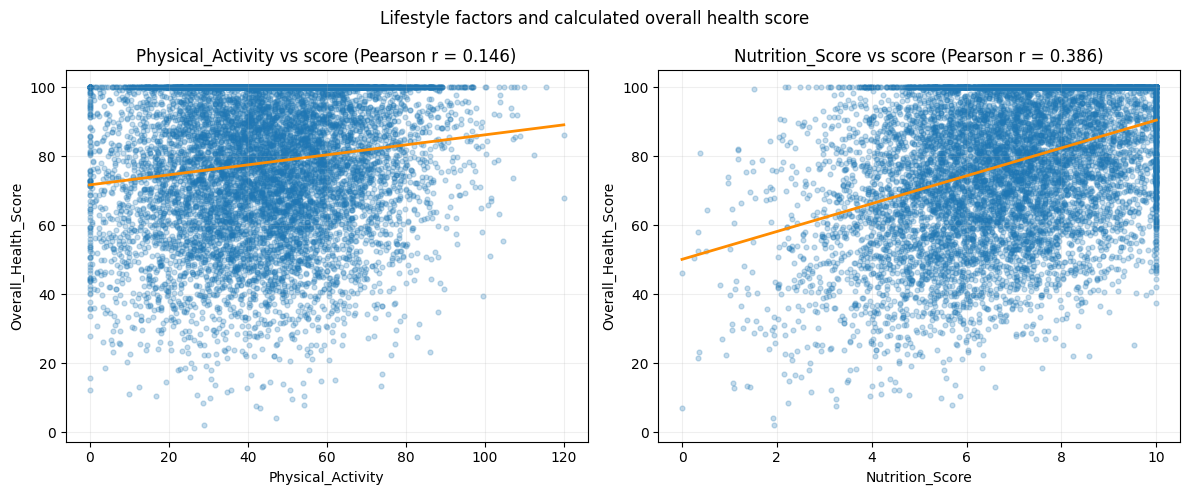

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, factor in zip(axes, correlation_pairs):
    pair = df[[factor, score_col]].dropna()
    ax.scatter(pair[factor], pair[score_col], alpha=0.25, s=12)
    slope, intercept = np.polyfit(pair[factor], pair[score_col], 1)
    x_line = np.linspace(pair[factor].min(), pair[factor].max(), 100)
    ax.plot(x_line, slope * x_line + intercept, color='darkorange', linewidth=2)
    r = correlation_results.loc[correlation_results['Factor'].eq(factor), 'Pearson r'].iloc[0]
    ax.set_title(f'{factor} vs score (Pearson r = {r:.3f})')
    ax.set_xlabel(factor)
    ax.set_ylabel(score_col)
    ax.grid(alpha=0.2)
fig.suptitle('Lifestyle factors and calculated overall health score')
fig.tight_layout()
fig.savefig("visuals/correlation_scatterplots.png", dpi=300, bbox_inches='tight')
plt.show()

### Findings
The scatterplots show an overall upward trend for both factors. The physical-activity pattern is relatively shallow, consistent with its weaker correlation; the nutrition pattern is more pronounced, consistent with its stronger correlation. The points still vary around each trend, so neither factor alone determines a record’s score.
### Conclusion: 
The visual patterns agree with the correlation table, while also making clear that the relationships are not exact.
### Next step: 
Move to framework Question 3 and compare score distributions for the two smoking groups.

## Interpret the correlation results

Read the Pearson r for direction and strength and its confidence interval for uncertainty. Holm-adjusted p-values for all three primary tests (the two correlations and the smoking mean comparison) are reported after the Welch test. A positive r means higher values of the factor tend to accompany higher scores. The Spearman result checks whether a monotonic relationship is also present without requiring a straight-line pattern. Statistical significance does not imply causation. Compare the recomputed values with the EDA values (Physical_Activity: 0.146; Nutrition_Score: 0.386); small rounding differences are expected. Spearman and Mann–Whitney are sensitivity checks and are kept outside the three-test Holm family.

# Section 3: Smoking-group hypothesis test (framework Question 3)

**Research question:** Is there a difference in overall health scores between smokers and non-smokers?

**H₀:** The population mean overall health score is equal for the two groups (μ_smoker − μ_non-smoker = 0).

**H₁:** The population mean overall health score differs between the two groups (μ_smoker − μ_non-smoker ≠ 0).

Use a two-sided test at α = 0.05. The approved question is non-directional; do not switch to a one-sided test after seeing the results.

## Inspect score distributions
The EDA reports a left-skewed score distribution and a ceiling at 100. The independent-groups t test compares means and is reasonably robust with these large group sizes, but we also inspect the distributions and run a Mann–Whitney test as a sensitivity check. Mann–Whitney tests distributional/rank differences; it is not itself a test of means.

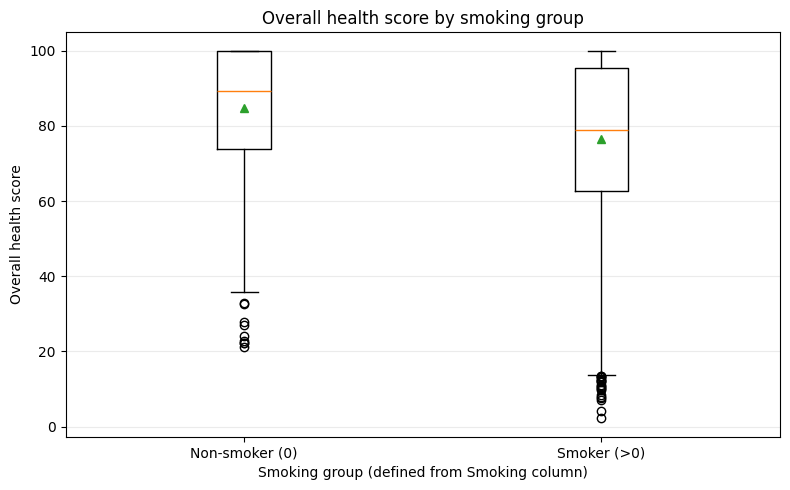

In [12]:
order = ['Non-smoker (0)', 'Smoker (>0)']
groups = [analysis.loc[analysis['Group'].eq(label), score_col].to_numpy() for label in order]
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(groups, labels=order, showmeans=True)
ax.set_title('Overall health score by smoking group')
ax.set_xlabel('Smoking group (defined from Smoking column)')
ax.set_ylabel('Overall health score')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
fig.savefig("visuals/smoking_score_by_group.png", dpi=300, bbox_inches='tight')
plt.show()

### Findings
The boxplot compares the score distributions for the two smoking groups and marks each group mean. The non-smoker group is centered higher: its mean is 84.84, compared with 76.58 for smokers. The distributions still show variation and overlap, so the plot alone does not establish whether the mean difference is statistically distinguishable from zero.
### Conclusion: 
The plot suggests a lower score distribution for smokers in this dataset, but I use the planned Welch test to quantify the mean difference and uncertainty.
### Next step: 
Run the two-sided Welch independent-samples t test.

## Primary test: Welch independent-samples t test
Welch’s t test is used as the primary test because it compares the two means without assuming equal group variances. The reported confidence interval is a 95% Welch interval for (smoker mean − non-smoker mean). Hedges’ g is the standardized mean difference, with a small-sample correction.

In [14]:
# Code developed with ChatGPT assistance.

non_smokers = analysis.loc[analysis[smoking_col].eq(0), score_col].to_numpy()
smokers = analysis.loc[analysis[smoking_col].gt(0), score_col].to_numpy()
if len(non_smokers) == 0 or len(smokers) == 0:
    raise ValueError('Both smoking groups must contain observations.')

welch = stats.ttest_ind(smokers, non_smokers, equal_var=False, alternative='two-sided')
difference = smokers.mean() - non_smokers.mean()
se = np.sqrt(smokers.var(ddof=1) / len(smokers) + non_smokers.var(ddof=1) / len(non_smokers))
v1 = smokers.var(ddof=1) / len(smokers)
v0 = non_smokers.var(ddof=1) / len(non_smokers)
welch_df = (v1 + v0) ** 2 / (v1 ** 2 / (len(smokers) - 1) + v0 ** 2 / (len(non_smokers) - 1))
critical_t = stats.t.ppf(0.975, welch_df)
ci_low, ci_high = difference - critical_t * se, difference + critical_t * se
pooled_sd = np.sqrt(((len(smokers)-1)*smokers.var(ddof=1) + (len(non_smokers)-1)*non_smokers.var(ddof=1)) / (len(smokers)+len(non_smokers)-2))
cohen_d = difference / pooled_sd
hedges_g = cohen_d * (1 - 3 / (4*(len(smokers)+len(non_smokers))-9))

print(f'Non-smokers: n={len(non_smokers):,}, mean={non_smokers.mean():.2f}, SD={non_smokers.std(ddof=1):.2f}')
print(f'Smokers:     n={len(smokers):,}, mean={smokers.mean():.2f}, SD={smokers.std(ddof=1):.2f}')
print(f'Mean difference (smoker - non-smoker) = {difference:.2f}')
print(f'95% CI for difference = [{ci_low:.2f}, {ci_high:.2f}]')
print(f'Welch t({welch_df:.1f}) = {welch.statistic:.3f}, two-sided p = {welch.pvalue:.3g}')
print(f'Hedges g = {hedges_g:.3f}')
alpha = 0.05
print('Decision:', 'Reject H0' if welch.pvalue < alpha else 'Do not reject H0')

# Holm adjustment across all three primary framework questions/tests.
primary_p_values = np.array([
    correlation_results.loc[correlation_results['Factor'].eq(factor), 'Pearson p'].iloc[0]
    for factor in correlation_pairs
] + [welch.pvalue])
test_names = list(correlation_pairs) + ['Smoking group mean difference']
sort_order = np.argsort(primary_p_values)
holm_adjusted = np.empty(len(primary_p_values))
running_max = 0.0
for rank, idx in enumerate(sort_order):
    running_max = max(running_max, (len(primary_p_values) - rank) * primary_p_values[idx])
    holm_adjusted[idx] = min(running_max, 1.0)

correlation_results['Holm-adjusted p (3 primary tests)'] = holm_adjusted[:2]
welch_holm_p = holm_adjusted[2]
print('Holm-adjusted p-values across the two correlations and smoking test:')
for name, p_value in zip(test_names, holm_adjusted):
    formatted_p = '<1e-300' if p_value == 0 else f'{p_value:.3g}'
    print(f'{name}: {formatted_p}')


Non-smokers: n=1,996, mean=84.84, SD=16.43
Smokers:     n=8,004, mean=76.58, SD=20.10
Mean difference (smoker - non-smoker) = -8.26
95% CI for difference = [-9.11, -7.42]
Welch t(3635.7) = -19.172, two-sided p = 4.05e-78
Hedges g = -0.425
Decision: Reject H0
Holm-adjusted p-values across the two correlations and smoking test:
Physical_Activity: 8.88e-49
Nutrition_Score: <1e-300
Smoking group mean difference: 8.11e-78


### Findings
The Welch test estimates the smoker-minus-non-smoker mean difference as −8.26 score points, with a 95% confidence interval from −9.11 to −7.42. The test result is t(3635.7) = −19.17, p = 4.05 × 10⁻⁷⁸. Hedges’ g = −0.43, a negative standardized difference of moderate size. Since the confidence interval excludes zero and both the unadjusted and three-test Holm-adjusted p-values are below 0.05, I reject the null hypothesis of equal group means for this dataset.
### Conclusion: 
The data support a difference in average scores, with the smoker group lower on average. This is an association in synthetic, formula-scored records, not evidence that smoking caused the difference.
### Next step: 
Check whether a rank-based sensitivity test gives a consistent result given the score’s skew and ceiling.
The two correlation null hypotheses are also rejected after the same Holm adjustment across all three primary tests.

## Sensitivity check: Mann–Whitney U
Because scores are skewed and capped, this non-parametric test checks whether the two score distributions differ in rank/location. Interpret it alongside the Welch test rather than as a replacement for the mean comparison.

In [15]:
mw = stats.mannwhitneyu(smokers, non_smokers, alternative='two-sided', method='asymptotic')
print(f'Mann–Whitney U = {mw.statistic:,.0f}, two-sided p = {mw.pvalue:.3g}')

Mann–Whitney U = 6,044,675, two-sided p = 2.41e-64


### Findings
The Mann–Whitney test is also statistically significant (U = 6,044,675; p = 2.41 × 10⁻⁶⁴). This provides a rank-based check that the groups’ score distributions differ; it is not a second test of the means. Its direction is consistent with the lower smoker scores seen in the descriptive statistics and Welch test.
### Conclusion: 
The sensitivity check supports the same overall interpretation, while the Welch test remains the direct test of the approved mean-difference hypothesis.
### Next step: 
Write my final summary using the effect sizes, confidence intervals, and limits of this synthetic dataset.

In [19]:
def format_p(value):
    return '<1e-300' if value == 0 else f'{value:.6g}'

result_rows = []
for index, row in correlation_results.iterrows():
    result_rows.append({
        'Family': 'Primary (Holm-adjusted across 3)',
        'Test': f"Pearson correlation: {row['Factor']}",
        'Estimate': row['Pearson r'],
        'CI_95_low': row['95% CI low'],
        'CI_95_high': row['95% CI high'],
        'Test_statistic': row['Pearson r'],
        'Degrees_of_freedom': len(df[[row['Factor'], score_col]].dropna()) - 2,
        'P_value': format_p(row['Pearson p']),
        'Holm_adjusted_P_value': format_p(row['Holm-adjusted p (3 primary tests)']),
        'Effect_size': row['Pearson r'],
        'Effect_size_name': 'Pearson r',
    })

result_rows.append({
    'Family': 'Primary (Holm-adjusted across 3)',
    'Test': 'Welch mean difference: smoker minus non-smoker',
    'Estimate': difference, 'CI_95_low': ci_low, 'CI_95_high': ci_high,
    'Test_statistic': welch.statistic, 'Degrees_of_freedom': welch_df,
    'P_value': format_p(welch.pvalue), 'Holm_adjusted_P_value': format_p(welch_holm_p),
    'Effect_size': hedges_g, 'Effect_size_name': 'Hedges g',
})

# Sensitivity checks are exported in a separate family without the primary Holm adjustment.
for _, row in correlation_results.iterrows():
    result_rows.append({
        'Family': 'Sensitivity (unadjusted)',
        'Test': f"Spearman correlation: {row['Factor']}",
        'Estimate': row['Spearman rho'], 'P_value': format_p(row['Spearman p']),
        'Effect_size': row['Spearman rho'], 'Effect_size_name': 'Spearman rho',
    })
result_rows.append({
    'Family': 'Sensitivity (unadjusted)', 'Test': 'Mann-Whitney U: smoker vs non-smoker',
    'Estimate': mw.statistic, 'Test_statistic': mw.statistic,
    'P_value': format_p(mw.pvalue),
})

# Save the CSV file to cleaned_datasets folder
results_path = Path("cleaned_datasets") / 'hypothesis_test_results.csv'
pd.DataFrame(result_rows).to_csv(results_path, index=False)
print(f"Results saved to: {results_path.resolve()}")

print("Charts saved to:")
print(Path("visuals/correlation_scatterplots.png").resolve())
print(Path("visuals/smoking_score_by_group.png").resolve())

Results saved to: C:\Projects\hackathon_project\Holistic-Health-and-Lifestyle-Score-Dataset\cleaned_datasets\hypothesis_test_results.csv
Charts saved to:
C:\Projects\hackathon_project\Holistic-Health-and-Lifestyle-Score-Dataset\visuals\correlation_scatterplots.png
C:\Projects\hackathon_project\Holistic-Health-and-Lifestyle-Score-Dataset\visuals\smoking_score_by_group.png


### My finding and handover
I saved a CSV summary of the primary tests and sensitivity checks, plus both charts in the project’s visual folder. I can share those three files with Vika. The CSV labels primary and sensitivity results separately, so the Holm-adjusted p-values are not confused with the unadjusted sensitivity checks.
### Next step: 
Hand the results to Vika and hand over to Hema’s notebook 04 for the predictive-modelling analysis.

# Conclusions and Next Steps
I found positive associations between the calculated overall health score and both physical activity (r = 0.146) and nutrition (r = 0.386). Nutrition had the stronger correlation. Both correlations and the smoking comparison remained statistically significant after Holm adjustment across all three primary tests, but the associations do not establish causation because the score is synthetic and formula-derived.
For the smoking comparison, I found a mean score of 76.58 among smokers and 84.84 among non-smokers. The smoker-minus-non-smoker difference was −8.26 points (95% CI −9.11 to −7.42), Welch’s t(3635.7) = −19.17, p = 4.05 × 10⁻⁷⁸, with Hedges’ g = −0.43. I rejected the null hypothesis of equal means for this dataset, including after the three-test Holm adjustment. The Mann–Whitney sensitivity check was also significant, supporting a difference in the score distributions.
These findings describe patterns in a synthetic dataset, not real-world health effects. The score is formula-based and capped at 100, so the score construction may shape the observed relationships.
### Next steps: 
Share the saved results and charts with Vika, then hand over to Hema’s notebook 04 for the predictive-modelling analysis. In that analysis, Overall_Health_Score should be excluded from the predictors because Health_Status is derived from it.